# JAM modal aerosol microphysics — the in-tree MAM4 core

This notebook walks through the in-tree modal microphysics core of JAM (`jam_microphysics="modal"`,
the `echam_physics()` default since D-A4): MAM4's five processes written in pure JAX, validated process
by process against the MAM4-JAX reference, conserving by construction, and differentiable end to end.

It is organised the way the work was validated:

1. **Equilibrium water uptake** — MAM's Köhler solve with the Kelvin term and deliquescence hysteresis (D-A6).
2. **The five processes, one at a time** — condensation, renaming, new-particle formation, coagulation, ageing — each
   with the closed form it was checked against.
3. **Conservation** — the per-process ledger on a populated column.
4. **Differentiability** — gradients of the core's outputs with respect to its tunables.
5. **A single column** — the black-carbon lifetime experiment.
6. **A short global run** — maps of the aerosol fields the core produces from the marine sources alone.

The design record with every decision and measured number is `docs/source/design/jam_modal_microphysics.md`;
the science register entry is `docs/source/science/aerosol.md` (*In-tree modal microphysics core*).

In [1]:
import dataclasses

import pandas as pd

import math
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np

import jcm.constants as c
from jcm.physics.aerosol.jam import MAM4_SPEC, mass_name, number_name
from jcm.physics.aerosol.jam.tracer_layout import gas_name
from jcm.physics.aerosol.jam.microphysics import (
    ageing, coagulation, condensation, koehler, moments,
    new_particle_formation as npf, rename,
)
from jcm.physics.aerosol.jam.microphysics.modal import (
    JamModalMicrophysics, MicrophysicsEnvironment, ModalPopulation, PROCESS_ORDER,
)

jax.config.update("jax_enable_x64", True)        # the research configuration; everything here also runs in float32
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("modes:", [(m.short, m.dgnum * 1e9, m.geom_std_dev) for m in MAM4_SPEC.modes])
print("process order:", [name for name, _ in PROCESS_ORDER])

modes: [('acc', 110.0, 1.8), ('ait', 26.0, 1.6), ('cor', 2000.0, 1.8), ('pcm', 50.0, 1.6)]
process order: ['gas_aerosol_exchange', 'rename', 'nucleation', 'coagulation', 'carbonaceous_ageing']


## 1. Equilibrium water uptake (D-A6)

The shared κ-Köhler state every JAM term reads is now MAM's `modal_aero_wateruptake`: the Köhler equilibrium
$\ln s = A/r - \kappa r_d^3/(r^3 - r_d^3)$ solved at the mode's volume-mean particle with the Kelvin coefficient
$A \approx 1.2$ nm, humidity capped at 0.98, and crystallization/deliquescence hysteresis — no water below
RH 0.35, the Köhler water volume scaled linearly to 0.80. Before this the state was pure κ-Köhler without the
Kelvin term or hysteresis, and against MAM4-JAX the Aitken mode came out up to 2× too wet at mid humidity.

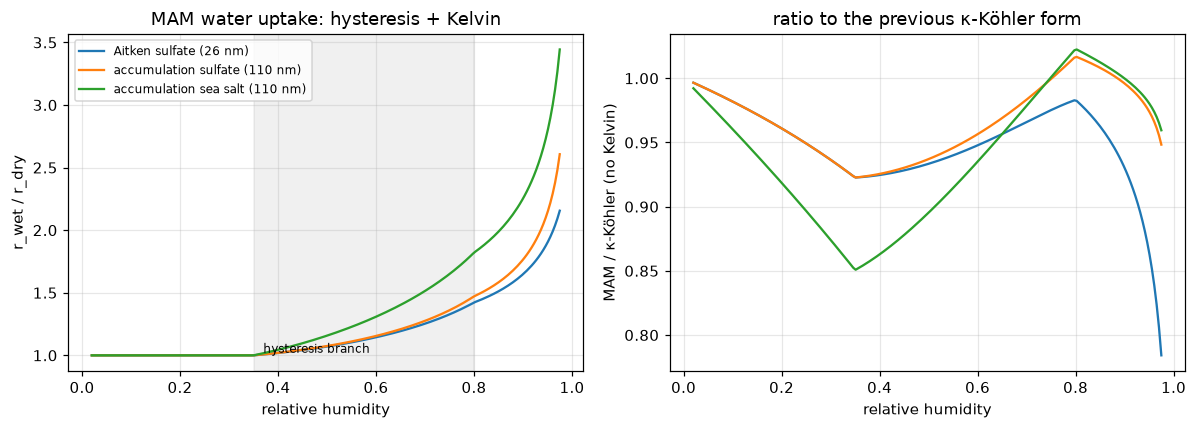

In [2]:
rh = jnp.linspace(0.02, 0.975, 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for mode, species, label in ((MAM4_SPEC.mode("aitken"), "so4", "Aitken sulfate (26 nm)"),
                             (MAM4_SPEC.mode("accum"), "so4", "accumulation sulfate (110 nm)"),
                             (MAM4_SPEC.mode("accum"), "ss", "accumulation sea salt (110 nm)")):
    kappa = MAM4_SPEC.species_props(species).hygroscopicity
    r_v = 0.5 * mode.dgnum * moments.moment_factor(mode, 3.0) ** (1 / 3)      # volume-mean particle
    g_mam = koehler.uptake_growth_factor(jnp.full(rh.shape, r_v), jnp.full(rh.shape, kappa), rh, mode)
    g_kk = jnp.cbrt(1.0 + kappa * rh / (1.0 - rh))                              # the old form, for contrast
    ax[0].plot(rh, g_mam, label=label)
    ax[1].plot(rh, g_mam / g_kk, label=label)
ax[0].set(xlabel="relative humidity", ylabel="r_wet / r_dry", title="MAM water uptake: hysteresis + Kelvin")
ax[1].set(xlabel="relative humidity", ylabel="MAM / κ-Köhler (no Kelvin)", title="ratio to the previous κ-Köhler form")
ax[0].axvspan(0.35, 0.80, color="k", alpha=0.06)
ax[0].text(0.37, 1.02, "hysteresis branch", fontsize=8)
ax[0].legend(fontsize=8)
plt.tight_layout()

## 2. The five processes

Every process is a pure function `population → population` on a `MicrophysicsEnvironment` frozen at the start
of the step, exactly as MAM freezes its uptake coefficients. We build one populated environment and reuse it.

In [3]:
SHAPE = (1, 1)
T, P, Q, DT = 285.0, 9.0e4, 0.005, 1800.0

def population(number=1e8, dg_scale=1.0, gas=1e-11):
    masses, numbers = {}, {}
    for m in MAM4_SPEC.modes:
        n = jnp.full(SHAPE, number)
        volume = moments.volume_from_diameter(n, m.dgnum * dg_scale, m)
        numbers[number_name(m.short)] = n
        for sp in m.species:
            masses[mass_name(sp, m.short)] = volume / len(m.species) * MAM4_SPEC.species_props(sp).density
    gases = {gas_name("h2so4"): jnp.full(SHAPE, gas), gas_name("soag"): jnp.full(SHAPE, gas),
             gas_name("so2"): jnp.full(SHAPE, 1e-10), gas_name("dms"): jnp.full(SHAPE, 1e-11)}
    return ModalPopulation(masses=masses, numbers=numbers, gases=gases)

def environment(pop, temperature=T, humidity=Q, pressure=P, height=500.0, pbl=1000.0):
    temp = jnp.full(SHAPE, temperature)
    pres = jnp.full(SHAPE, pressure)
    sat = koehler.saturation_ratio(temp, jnp.full(SHAPE, humidity), pres)
    return MicrophysicsEnvironment(
        temperature=temp, pressure=pres, saturation=sat, air_density=pres / (c.rd * temp),
        state_start=koehler.equilibrium_modal_state(pop.masses, pop.numbers, MAM4_SPEC, sat),
        h2so4_production=jnp.zeros(SHAPE), height_above_surface=jnp.full(SHAPE, height),
        pbl_height=jnp.full(SHAPE[1:], pbl), dt=DT,
        dry_volume_start={m.short: moments.mode_volume(pop.masses, m, MAM4_SPEC) for m in MAM4_SPEC.modes})

pop0 = population()
env0 = environment(pop0)
print({m.short: f"dg {float(2*env0.state_start.r_dry[i,0,0])*1e9:.1f} nm, wet {float(2*env0.state_start.r_wet[i,0,0])*1e9:.1f} nm, kappa {float(env0.state_start.kappa[i,0,0]):.2f}"
       for i, m in enumerate(MAM4_SPEC.modes)})

{'acc': 'dg 110.0 nm, wet 115.6 nm, kappa 0.28', 'ait': 'dg 26.0 nm, wet 28.0 nm, kappa 0.48', 'cor': 'dg 2000.0 nm, wet 2103.9 nm, kappa 0.28', 'pcm': 'dg 50.0 nm, wet 50.3 nm, kappa 0.04'}


### 2a. Gas–aerosol exchange

Fuchs–Sutugin uptake with Fuller diffusivity, integrated over each mode by two-point Gauss–Hermite quadrature
on the **wet** diameter (MAM's `gas_aer_exch` documentation). H₂SO₄ is nonvolatile; SOAG condenses reversibly
against Raoult's law. The per-mode uptake coefficient scales as $D^2$ in the free-molecular regime and $D$ in the
continuum regime — the two-point quadrature with MAM's `β` exponent is exact in both limits.

H2SO4 depletion this step: 0.9999999999999957
sulfate gained per mode [kg/kg]: {'acc': '2.17e-13', 'ait': '1.05e-14', 'cor': '1.15e-11'}  shell on primary carbon (coating): {'so4': '3.26e-14', 'soa': '1.00e-12'}


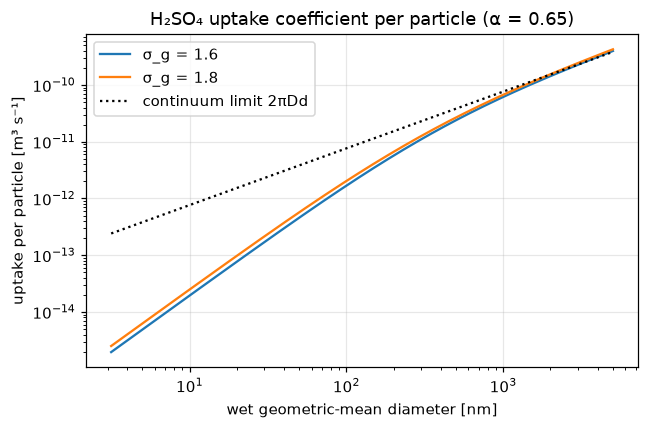

In [4]:
params = condensation.CondensationParameters()
diffusivity = condensation.gas_diffusivity(jnp.asarray(T), jnp.asarray(P), 0.0980784, params.diffusion_volume_h2so4)
mean_free_path = 3.0 * diffusivity / condensation.mean_molecular_speed(jnp.asarray(T), 0.0980784)
d = jnp.logspace(-8.5, -5.3, 200)
fig, ax = plt.subplots(figsize=(6, 4))
for sigma in (1.6, 1.8):
    coeff = condensation.mass_transfer_coefficient(1.0, d, math.log(sigma), diffusivity, mean_free_path, params.accommodation)
    ax.loglog(d * 1e9, coeff, label=f"σ_g = {sigma}")
ax.loglog(d * 1e9, 2 * math.pi * diffusivity * d, "k:", label="continuum limit 2πDd")
ax.set(xlabel="wet geometric-mean diameter [nm]", ylabel="uptake per particle [m³ s⁻¹]",
       title="H₂SO₄ uptake coefficient per particle (α = 0.65)")
ax.legend()
plt.tight_layout()

# one step on the populated environment: where does the vapour go?
out = condensation.condense(pop0, env0, MAM4_SPEC, params)
gained = {m.short: float((out.masses[mass_name("so4", m.short)] - pop0.masses[mass_name("so4", m.short)])[0, 0])
          for m in MAM4_SPEC.modes if "so4" in m.species}
print("H2SO4 depletion this step:", float(out.diagnostics["condensation_h2so4_depletion"][0, 0]))
print("sulfate gained per mode [kg/kg]:", {k: f"{v:.2e}" for k, v in gained.items()},
      " shell on primary carbon (coating):", {k: f"{float(v[0,0]):.2e}" for k, v in out.coating.items()})

### 2b. Renaming

After exchange, the part of the Aitken distribution above the cut diameter between the modes
($D_{cut} = \sqrt{D_{v,ait} D_{v,acc}} \approx 55$ nm) is accumulation-mode by definition and is moved there
(Easter et al. 2004; E3SM `modal_aero_rename.F90`). Fractions are erfc tail integrals; the number fraction is
capped by the volume fraction; renaming acts on the interstitial and cloud-borne phases alike (D-A5).

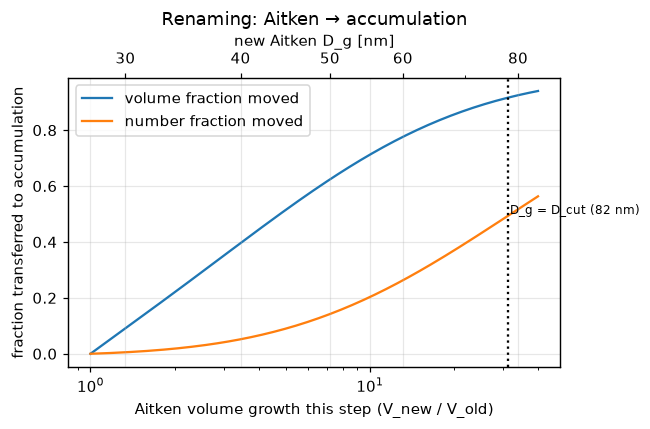

In [5]:
ait, acc = MAM4_SPEC.mode("aitken"), MAM4_SPEC.mode("accum")
cut = rename.cut_diameter(ait, acc)
number = 1e9
v_ref = moments.volume_from_diameter(number, ait.dgnum, ait)
growth = jnp.logspace(0.0, jnp.log10(40.0), 160)      # up to and past the cut (volume growth of 31 in one step)
xv, xn = jax.vmap(lambda g: jnp.stack(rename.transfer_fractions(v_ref, v_ref * g, number, ait, acc)))(growth).T
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(growth, xv, label="volume fraction moved")
ax.plot(growth, xn, label="number fraction moved")
dg_new = ait.dgnum * growth ** (1 / 3)
ax.set_xscale("log")
ax2 = ax.twiny()
ax2.set_xscale("log")
ax2.set_xlim(dg_new[0] * 1e9, dg_new[-1] * 1e9)
ax2.set_xlabel("new Aitken D_g [nm]")
ax2.xaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter())
ax2.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax2.set_xticks([30, 40, 50, 60, 80])
ax.axvline((cut / ait.dgnum) ** 3, color="k", ls=":")
ax.text((cut / ait.dgnum) ** 3 * 1.02, 0.5, f"D_g = D_cut ({cut*1e9:.0f} nm)", fontsize=8)
ax.set(xlabel="Aitken volume growth this step (V_new / V_old)", ylabel="fraction transferred to accumulation",
       title="Renaming: Aitken → accumulation")
ax.legend(loc="upper left")
plt.tight_layout()

### 2c. New-particle formation

Binary H₂SO₄–H₂O formation (Vehkamäki et al. 2002 — the same function as MAM4-JAX to four figures) plus the
boundary-layer first-order pathway (Sihto et al. 2006) below max(PBL top, 100 m); Kerminen & Kulmala (2002)
survival from the critical cluster to the Aitken lower bound, with MAM's condensation sink built from the
exchange step's uptake. Below MAM's 1e-6 cm⁻³ s⁻¹ there is no formation at all.

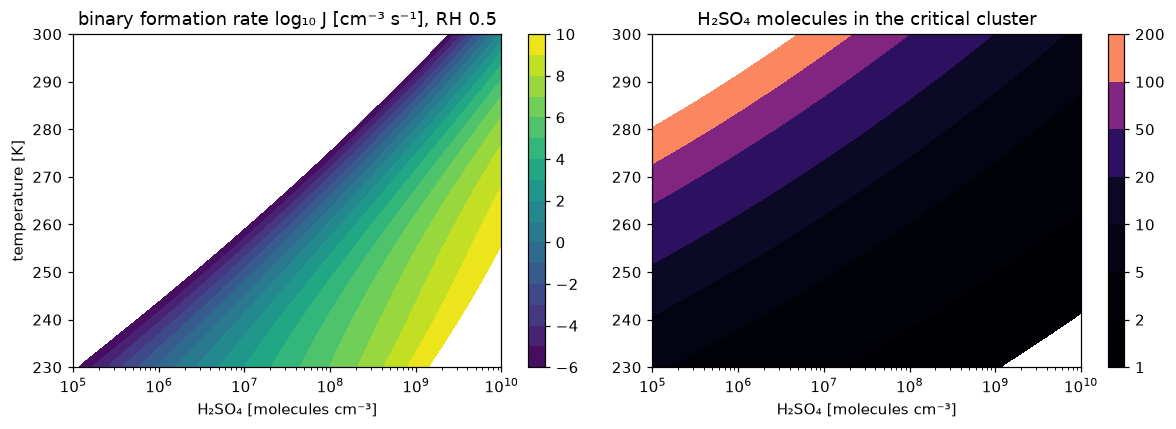

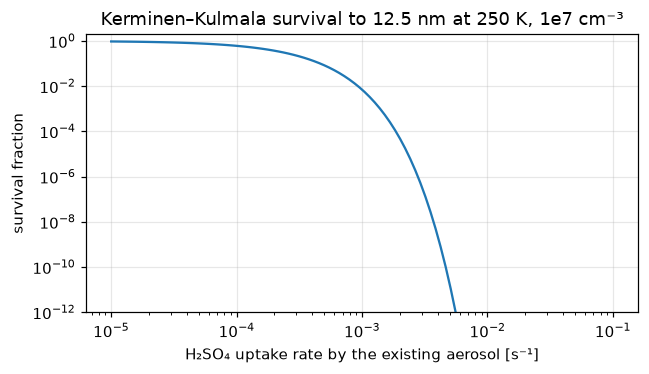

In [6]:
temps = jnp.linspace(230.0, 300.0, 80)
concs = jnp.logspace(5, 10, 80)
TT, CC = jnp.meshgrid(temps, concs, indexing="ij")
rate, n_h2so4, radius = npf.binary_formation(TT, jnp.full(TT.shape, 0.5), CC)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cs = ax[0].contourf(np.asarray(CC), np.asarray(TT), np.log10(np.maximum(np.asarray(rate), 1e-12)), levels=np.arange(-6, 11, 1), cmap="viridis")
ax[0].set_xscale("log")
ax[0].set(xlabel="H₂SO₄ [molecules cm⁻³]", ylabel="temperature [K]", title="binary formation rate log₁₀ J [cm⁻³ s⁻¹], RH 0.5")
plt.colorbar(cs, ax=ax[0])
ax[0].grid(False)
cs2 = ax[1].contourf(np.asarray(CC), np.asarray(TT), np.asarray(n_h2so4), levels=[1, 2, 5, 10, 20, 50, 100, 200], cmap="magma")
ax[1].set_xscale("log")
ax[1].set(xlabel="H₂SO₄ [molecules cm⁻³]", title="H₂SO₄ molecules in the critical cluster")
plt.colorbar(cs2, ax=ax[1])
ax[1].grid(False)
plt.tight_layout()

# survival to the Aitken bound against the condensation sink
uptake = jnp.logspace(-5, -1, 100)
air_moles = jnp.asarray(P / (c.r_universal * 250.0))
apparent, _ = npf.survival_to_aitken(jnp.ones_like(uptake), jnp.full_like(uptake, 30.0), jnp.full_like(uptake, 0.5e-9),
                                     jnp.asarray(250.0), jnp.asarray(0.5), jnp.asarray(1e7), uptake, air_moles)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(uptake, apparent)
ax.set(xlabel="H₂SO₄ uptake rate by the existing aerosol [s⁻¹]", ylabel="survival fraction",
       title="Kerminen–Kulmala survival to 12.5 nm at 250 K, 1e7 cm⁻³")
ax.set_ylim(1e-12, 2.0)
plt.tight_layout()

### 2d. Coagulation

CMAQ v4.6 fast coefficients (Whitby et al. 1991 analytic moment integrals, Binkowski & Roselle 2003 correction
tables, harmonic mean of the free-molecular and near-continuum limits), as E3SM's `modal_aero_coag.F90` carries
them — Aitken, accumulation and primary carbon only. Checked against brute-force quadrature of the same kernels
(+3…7 % at MAM4 geometry, the method's own bias) and exact in the monodisperse limit.

number lost this step: {'acc': '0.02%', 'ait': '0.23%', 'pcm': '0.08%'}


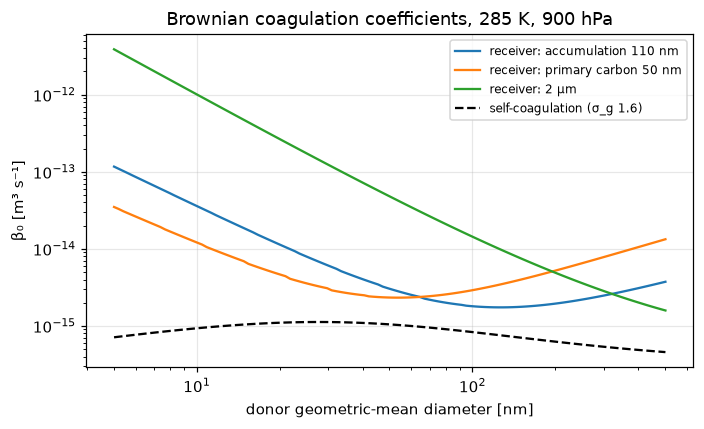

In [7]:
lam, mu = coagulation.air_properties(jnp.asarray(T), jnp.asarray(P))
d_i = jnp.logspace(-8.3, -6.3, 120)
fig, ax = plt.subplots(figsize=(6.5, 4))
for d_j, label in ((110e-9, "receiver: accumulation 110 nm"), (50e-9, "receiver: primary carbon 50 nm"), (2e-6, "receiver: 2 µm")):
    b0, b3 = coagulation.intermodal_coefficients(d_i, jnp.full_like(d_i, 1770.0), 1.6,
                                                 jnp.full_like(d_i, d_j), jnp.full_like(d_i, 1770.0), 1.8,
                                                 jnp.asarray(T), lam, mu)
    ax.loglog(d_i * 1e9, b0, label=label)
self_ = jax.vmap(lambda d: coagulation.intramodal_coefficient(d, jnp.asarray(1770.0), 1.6, jnp.asarray(T), lam, mu))(d_i)
ax.loglog(d_i * 1e9, self_, "k--", label="self-coagulation (σ_g 1.6)")
ax.set(xlabel="donor geometric-mean diameter [nm]", ylabel="β₀ [m³ s⁻¹]", title="Brownian coagulation coefficients, 285 K, 900 hPa")
ax.legend(fontsize=8)
plt.tight_layout()

out = coagulation.coagulate(pop0, env0, MAM4_SPEC, None)
print("number lost this step:", {m.short: f"{1 - float(out.numbers[number_name(m.short)][0,0] / pop0.numbers[number_name(m.short)][0,0]):.2%}"
                                for m in MAM4_SPEC.modes if m.short != "cor"})

### 2e. Carbonaceous ageing

Primary carbon is `can_activate=False`: structurally excluded from activation and in-cloud scavenging until it is
coated. The shell of sulfate plus κ-equivalent SOA deposited this step (by exchange and coagulation, carried across
the seam in `population.coating`) is compared, as a thickness over the mode's surface, with `n_so4_monolayers`
(8 — MAM4's published value; E3SMv3 uses 3) of 4.76 Å; that fraction of the mode's POA, BC, marine organics and
number moves to accumulation.

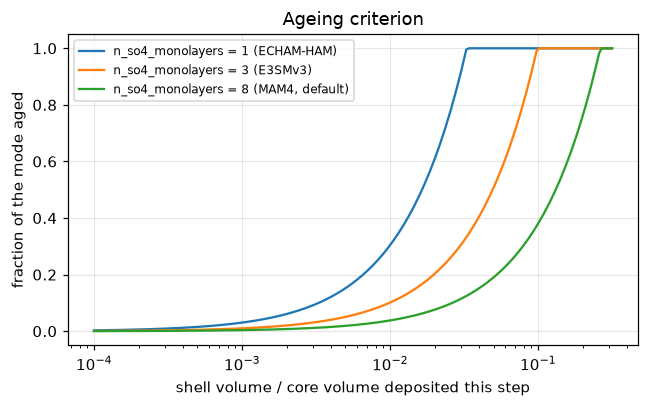

In [8]:
pcm = MAM4_SPEC.mode("primary_carbon")
core_volume = jnp.asarray(1e-13)                          # m³ per kg of air
shell = jnp.logspace(-17, -13.5, 200)
fig, ax = plt.subplots(figsize=(6, 3.8))
for n in (1.0, 3.0, 8.0):
    f = jax.vmap(lambda s: ageing.aged_fraction(s, core_volume, jnp.asarray(50e-9), pcm.geom_std_dev, n))(shell)
    ax.semilogx(shell / core_volume, f, label=f"n_so4_monolayers = {n:g}" + (" (MAM4, default)" if n == 8 else " (E3SMv3)" if n == 3 else " (ECHAM-HAM)"))
ax.set(xlabel="shell volume / core volume deposited this step", ylabel="fraction of the mode aged", title="Ageing criterion")
ax.legend(fontsize=8)
plt.tight_layout()

## 3. Conservation: the ledger

`JamModalMicrophysics(audit=True)` publishes the relative change of every reservoir total after each process —
sulfur moles, organic mass, each inert species, total number — against the contract each process must keep.

step closure: {'sulfur': '2.2e-16', 'organic': '1.4e-15', 'number': '1.3e+02'}


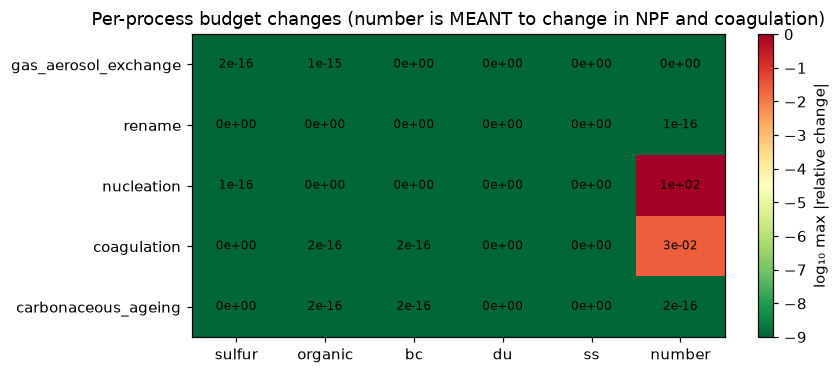

In [9]:
from jcm.physics_interface import PhysicsState
NLEV, NCOLS = 6, 4
rng = np.random.default_rng(0)
tracers = {}
for m in MAM4_SPEC.modes:
    n = jnp.asarray(10 ** rng.uniform(6, 9, (NLEV, NCOLS)))
    dg = jnp.asarray(np.exp(rng.uniform(np.log(m.dgnum_lo * 1.2), np.log(m.dgnum_hi / 1.2), (NLEV, NCOLS))))
    volume = moments.volume_from_diameter(n, dg, m)
    w = rng.dirichlet(np.ones(len(m.species)), size=(NLEV, NCOLS))
    tracers[number_name(m.short)] = n
    for j, sp in enumerate(m.species):
        tracers[mass_name(sp, m.short)] = volume * jnp.asarray(w[..., j]) * MAM4_SPEC.species_props(sp).density
tracers.update({gas_name("h2so4"): jnp.asarray(10 ** rng.uniform(-13, -10, (NLEV, NCOLS))), gas_name("soag"): jnp.full((NLEV, NCOLS), 1e-10),
                gas_name("so2"): jnp.full((NLEV, NCOLS), 1e-10), gas_name("dms"): jnp.full((NLEV, NCOLS), 1e-11)})
state = PhysicsState.zeros((NLEV, NCOLS)).copy(temperature=jnp.asarray(rng.uniform(240, 300, (NLEV, NCOLS))),
                                               specific_humidity=jnp.asarray(rng.uniform(1e-4, 8e-3, (NLEV, NCOLS))), tracers=tracers)
diagnostics = {"pressure_full": jnp.asarray(rng.uniform(3e4, 1e5, (NLEV, NCOLS))), "_dt_seconds": DT}
tendency, out = JamModalMicrophysics(audit=True)(state, diagnostics, None, None)

budgets = ["sulfur", "organic", "bc", "du", "ss", "number"]
table = np.array([[float(jnp.max(jnp.abs(out[f"_modal_ledger_{name}_{b}"]))) for b in budgets] for name, _ in PROCESS_ORDER])
fig, ax = plt.subplots(figsize=(8, 3.5))
im = ax.imshow(np.log10(np.maximum(table, 1e-9)), cmap="RdYlGn_r", vmin=-9, vmax=0, aspect="auto")
ax.set_xticks(range(len(budgets)))
ax.set_xticklabels(budgets)
ax.set_yticks(range(len(PROCESS_ORDER)))
ax.set_yticklabels([n for n, _ in PROCESS_ORDER])
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        ax.text(j, i, f"{table[i,j]:.0e}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="log₁₀ max |relative change|")
ax.set_title("Per-process budget changes (number is MEANT to change in NPF and coagulation)")
ax.grid(False)
plt.tight_layout()
print("step closure:", {b: f"{float(jnp.max(jnp.abs(out[f'_modal_ledger_step_{b}']))):.1e}" for b in ("sulfur", "organic", "number")})

## 4. Differentiability

Every tunable is a `flax.struct` leaf on the core. Here: the sensitivity of the step's tracer tendencies to each
parameter, by reverse-mode AD through the whole process fold. The two float32 trap classes found while building
this (dead-branch `tiny²` and live-quotient `cot·y⁻²` overflow) are gone; this cell runs in float64 but the same
gradients are finite in float32 (`modal_gradients_test.py`).

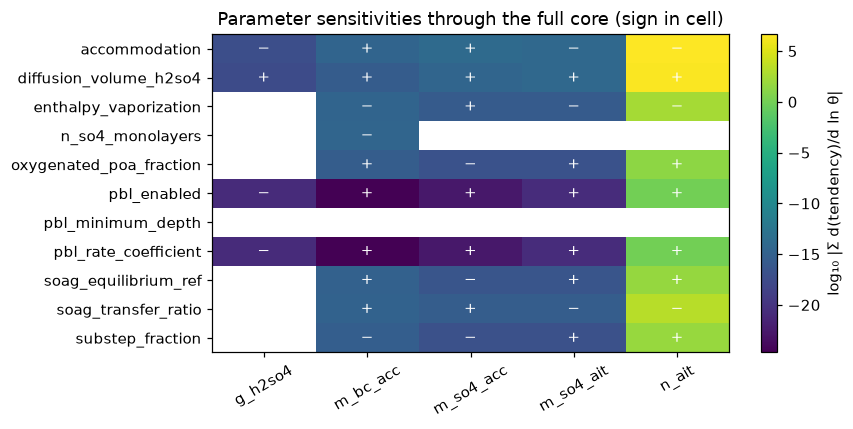

In [10]:
def tendency_projection(cond_p, npf_p, age_p, key):
    core = JamModalMicrophysics(condensation_params=cond_p, npf_params=npf_p, ageing_params=age_p)
    tend, _ = core(state, diagnostics, None, None)
    return jnp.sum(tend.tracers[key])

params = (condensation.CondensationParameters(), npf.NewParticleFormationParameters(), ageing.AgeingParameters())
rows = []
for key in ("n_ait", "m_so4_ait", "m_so4_acc", "m_bc_acc", "g_h2so4"):
    grads = jax.grad(tendency_projection, argnums=(0, 1, 2))(*params, key)
    for struct, g in zip(params, grads):
        for f in dataclasses.fields(struct):
            value = getattr(struct, f.name)
            grad = getattr(g, f.name)
            if jnp.issubdtype(jnp.result_type(value), jnp.floating):
                rows.append((key, f.name, float(grad) * float(value)))        # d(tendency)/d(ln parameter)
df = pd.DataFrame(rows, columns=["output", "parameter", "d tendency / d ln parameter"]).pivot(index="parameter", columns="output", values="d tendency / d ln parameter")
fig, ax = plt.subplots(figsize=(8, 4))
sign = np.sign(df.values)
mag = np.log10(np.maximum(np.abs(df.values), 1e-30))
im = ax.imshow(np.where(np.abs(df.values) > 0, mag, np.nan), cmap="viridis", aspect="auto")
ax.set_xticks(range(df.shape[1]))
ax.set_xticklabels(df.columns, rotation=30)
ax.set_yticks(range(df.shape[0]))
ax.set_yticklabels(df.index)
for i in range(df.shape[0]):
    for j in range(df.shape[1]):
        ax.text(j, i, "+" if sign[i, j] > 0 else ("−" if sign[i, j] < 0 else "0"), ha="center", va="center", color="w")
plt.colorbar(im, ax=ax, label="log₁₀ |Σ d(tendency)/d ln θ|")
ax.set_title("Parameter sensitivities through the full core (sign in cell)")
ax.grid(False)
plt.tight_layout()

## 5. A single column: the black-carbon lifetime

The release-validation column (a prescribed tropical convective sounding re-imposed every step; `jcm.rce`),
run three ways for six days: BC seeded in primary carbon under the inert placeholder core; the same mass seeded
in accumulation; and BC in primary carbon under the modal core with a sustained polluted sulfuric-acid vapour.
Ageing opens the in-cloud removal path — one column cannot give a global lifetime (no transport, and a convective
column rains far above the global mean), so what is shown is the mechanism and its magnitude here.

three six-day columns in 122 s


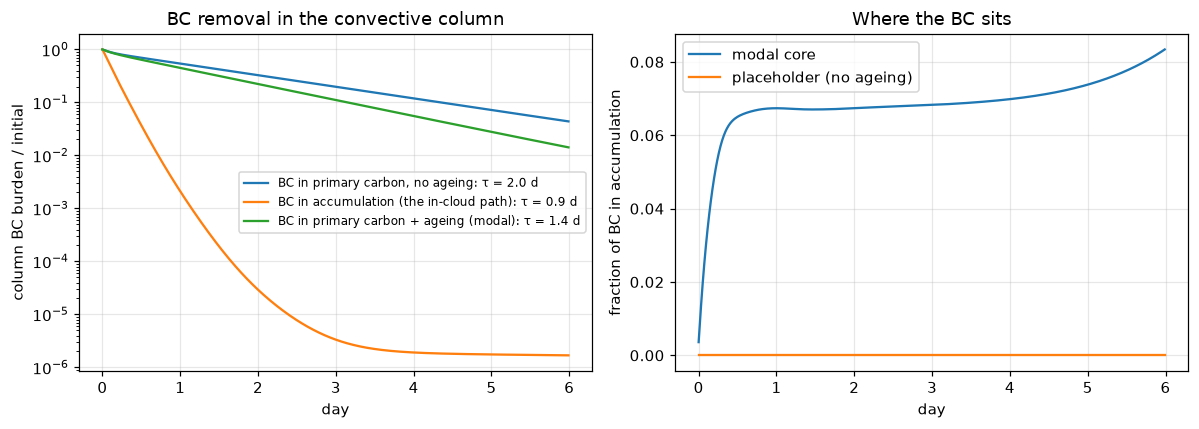

In [11]:
from jcm.physics.aerosol.jam.microphysics import bc_lifetime_test as bc   # the slow test's column, reused
DAYS = 6.0
t0 = time.time()
t, pcm_off, acc_leak = bc._run("placeholder", DAYS, seed_mode="pcm")
_, pcm_acc, acc_only = bc._run("placeholder", DAYS, seed_mode="acc")
_, pcm_on, acc_on = bc._run("modal", DAYS, seed_mode="pcm", sustained_h2so4=1.0e-11)
print(f"three six-day columns in {time.time() - t0:.0f} s")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for label, total in (("BC in primary carbon, no ageing", pcm_off + acc_leak), ("BC in accumulation (the in-cloud path)", pcm_acc + acc_only),
                     ("BC in primary carbon + ageing (modal)", pcm_on + acc_on)):
    ax[0].semilogy(t, total / total[0], label=f"{label}: τ = {bc._lifetime_days(t, total, 1.0):.1f} d")
ax[0].set(xlabel="day", ylabel="column BC burden / initial", title="BC removal in the convective column")
ax[0].legend(fontsize=8)
ax[1].plot(t, acc_on / (pcm_on + acc_on), label="modal core")
ax[1].plot(t, acc_leak / (pcm_off + acc_leak), label="placeholder (no ageing)")
ax[1].set(xlabel="day", ylabel="fraction of BC in accumulation", title="Where the BC sits")
ax[1].legend()
plt.tight_layout()

## 6. A short global run

T21 with 20 sigma layers, the idealized ECHAM physics (grey radiation) with JAM and the modal core — the
configuration `jam_integration_test.py` runs — on an aquaplanet with prescribed SSTs, from rest, with the marine
sources that surface drives: sea salt from the wind, DMS from a prescribed seawater concentration, SO₂ → H₂SO₄ by
the prescribed oxidants, and from there everything the core does — condensation, new particles, coagulation,
ageing, activation into the two-moment cloud scheme. From rest the circulation takes days to develop, so the
early maps are the chemistry's, the later ones the wind's.

Why not real terrain: the packaged T63 (and T30) orography on this coarse grid excites the documented
ECHAM orography × surface-flux instability (`jcm/physics/echam/echam_with_land_test.py`), which blows the
run up within hours **with or without an aerosol module** (checked with `aerosol_module="macv2sp"` and with the
placeholder core, which fail identically) — it is a dynamics/surface problem, not this core's. The validated
realistic configuration is the T63L47 `physics=echam-jam` Hydra config (dust from the data-mirror source
tables, CEDS emissions, RRTMGP), a GPU run: `python -m jcm.main +configuration=t63-echam-jam physics.jam_microphysics=modal`.

In [12]:
from jcm.model import Model
from jcm.physics.echam.testing import idealized_echam_physics
from jcm.terrain import TerrainData
from jcm.forcing import default_forcing
from jcm.utils import get_coords

N_DAYS = 10.0
coords = get_coords(np.linspace(0, 1, 21), spectral_truncation=21)
terrain = TerrainData.aquaplanet(coords)
forcing = default_forcing(coords.horizontal)                                            # the fixed aquaplanet SSTs
forcing = forcing.copy(dms_seawater=jnp.full(coords.horizontal.nodal_shape, 1.5e-7))     # ~2.5 nmol/L, a mid-ocean value
physics = idealized_echam_physics(aerosol_module="jam", cloud_scheme="2m")              # jam_microphysics="modal" is the default
print("microphysics core:", next(t for t in physics.terms if t.category == "aerosol_microphysics").name)
model = Model(coords=coords, time_step=30, terrain=terrain, physics=physics)
t0 = time.time()
predictions = model.run(save_interval=0.5, total_time=N_DAYS, forcing=forcing)
ds = predictions.to_xarray()
print(f"{N_DAYS} days in {time.time() - t0:.0f} s; output variables: {len(ds.data_vars)}")

microphysics core: jam_modal_microphysics


/data/lkemp/jax-gcm-aerosol/jcm/physics/composable_physics.py:202: UserWarning: SundqvistCloudFraction: its parameter defaults were built for T63 but the model grid is T21. Build the physics with the grid (echam_physics(coords=...); the Hydra runner does this) to get the grid's defaults, or pass the parameters explicitly.
  term.cache_coords(coords)
/data/lkemp/jax-gcm-aerosol/jcm/physics/composable_physics.py:202: UserWarning: Lohmann2MMicrophysics: its parameter defaults were built for T63 but the model grid is T21. Build the physics with the grid (echam_physics(coords=...); the Hydra runner does this) to get the grid's defaults, or pass the parameters explicitly.
  term.cache_coords(coords)


10.0 days in 1894 s; output variables: 365


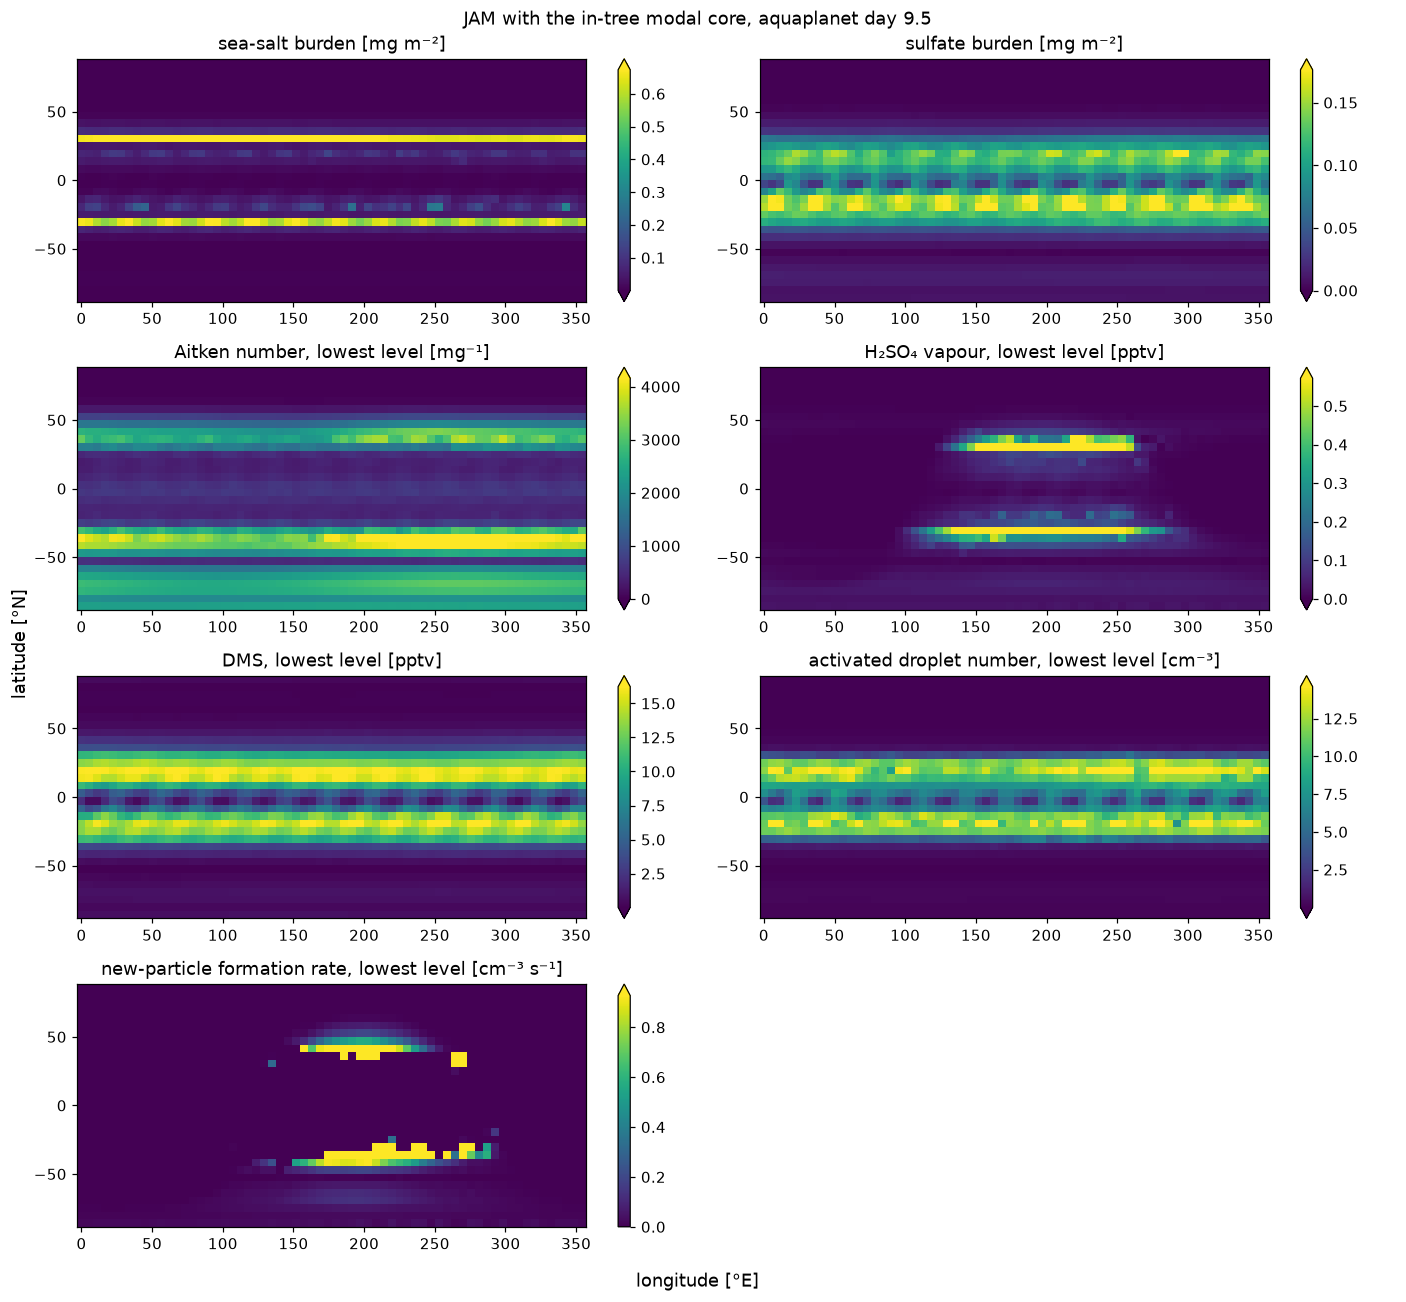

In [13]:
def column_burden(da):
    # Σ q Δp / g over the level axis; the saved output is surface-first on both vertical axes.
    # The interface pressure is taken at the field's own time(s), so a time-sliced field gets a
    # time-sliced Δp rather than broadcasting against the whole history.
    phalf = ds["pressure_half"].sel(time=da["time"])
    dp = -phalf.diff("level_i").rename({"level_i": "level"}).assign_coords(level=ds.level)
    return (da * dp).sum("level") / c.grav

last = ds.isel(time=-1)
fields = {
    "sea-salt burden [mg m⁻²]": 1e6 * (column_burden(last["m_ss_acc"]) + column_burden(last["m_ss_cor"])),
    "sulfate burden [mg m⁻²]": 1e6 * sum(column_burden(last[f"m_so4_{m}"]) for m in ("ait", "acc", "cor")),
    "Aitken number, lowest level [mg⁻¹]": 1e-6 * last["n_ait"].isel(level=0),
    "H₂SO₄ vapour, lowest level [pptv]": last["g_h2so4"].isel(level=0) * 28.966 / 98.08 * 1e12,
    "DMS, lowest level [pptv]": last["g_dms"].isel(level=0) * 28.966 / 62.13 * 1e12,
    "activated droplet number, lowest level [cm⁻³]": 1e-6 * last["activated_cdnc"].isel(level=0) if "activated_cdnc" in ds else None,
    "new-particle formation rate, lowest level [cm⁻³ s⁻¹]": last["modal_npf_rate_apparent"].isel(level=0) if "modal_npf_rate_apparent" in ds else None,
}
fields = {k: v for k, v in fields.items() if v is not None}
fig, axes = plt.subplots(4, 2, figsize=(13, 12))
for ax in axes.ravel()[len(fields):]:
    ax.set_axis_off()
for ax, (title, da) in zip(axes.ravel(), fields.items()):
    da.plot(ax=ax, x="lon", y="lat", cmap="viridis", robust=True, cbar_kwargs={"label": ""})
    ax.set(title=title, xlabel="", ylabel="")
    ax.grid(False)
fig.supxlabel("longitude [°E]")
fig.supylabel("latitude [°N]")
day = float((last.time - ds.time[0]) / np.timedelta64(1, "D"))
plt.suptitle(f"JAM with the in-tree modal core, aquaplanet day {day:.1f}")
plt.tight_layout()

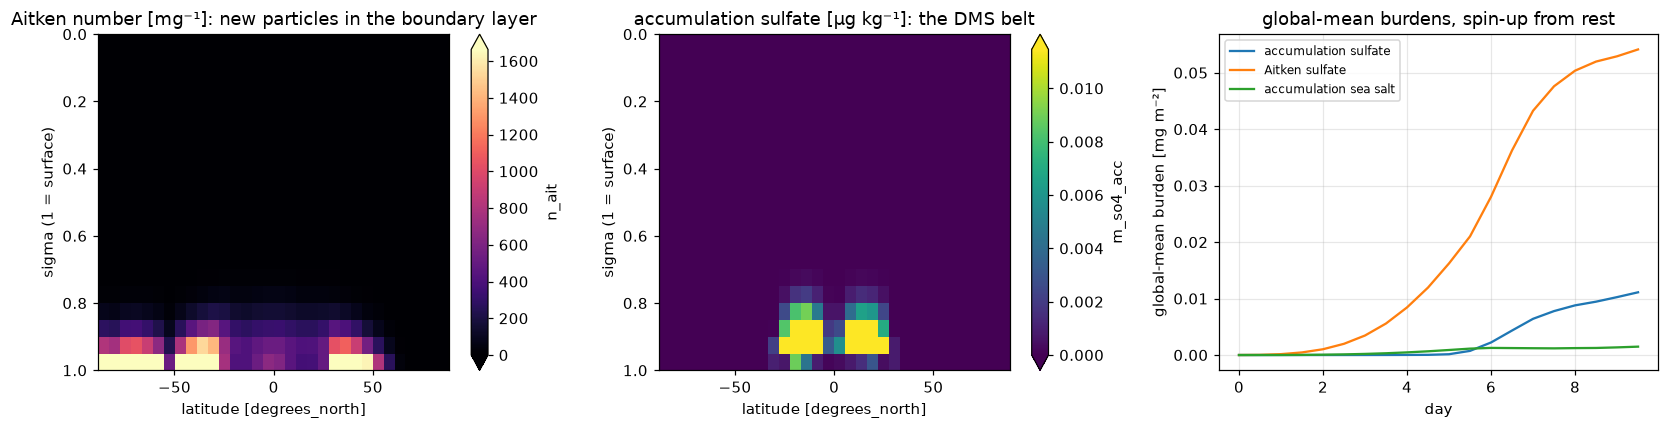

In [14]:
# zonal-mean structure and the time evolution of the global burdens
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
(1e-6 * ds["n_ait"]).isel(time=-1).mean("lon").plot(ax=ax[0], x="lat", y="level", yincrease=False, cmap="magma", robust=True)
ax[0].set(title="Aitken number [mg⁻¹]: new particles in the boundary layer", ylabel="sigma (1 = surface)")
ax[0].grid(False)
(1e9 * ds["m_so4_acc"]).isel(time=-1).mean("lon").plot(ax=ax[1], x="lat", y="level", yincrease=False, cmap="viridis", robust=True)
ax[1].set(title="accumulation sulfate [µg kg⁻¹]: the DMS belt", ylabel="sigma (1 = surface)")
ax[1].grid(False)
weights = np.cos(np.deg2rad(ds.lat))
for key, label in (("m_so4_acc", "accumulation sulfate"), ("m_so4_ait", "Aitken sulfate"), ("m_ss_acc", "accumulation sea salt")):
    burden = column_burden(ds[key]).weighted(weights).mean(("lat", "lon"))
    ax[2].plot((ds.time - ds.time[0]) / np.timedelta64(1, "D"), 1e6 * burden, label=label)
ax[2].set(xlabel="day", ylabel="global-mean burden [mg m⁻²]", title="global-mean burdens, spin-up from rest")
ax[2].legend(fontsize=8)
plt.tight_layout()

## What was validated, in one place

| Check | Where | Result |
|---|---|---|
| Closed forms per process | `*_test.py` under `microphysics/` | coagulation vs quadrature +3…7 %; renaming vs MAM per-cell transcription; ageing vs monodisperse cases; Köhler vs `numpy.roots` |
| Conservation | `ledger_test.py` | every process keeps its contract to 1e-5 in float32, with and without the cloud-borne phase |
| Differentiability | `modal_gradients_test.py`, `term_gradients_test.py` | forward and reverse finite at ten operating points and on the ECHAM column; AD = central difference in float64 |
| Reference A/B | `ab_mam4_jax_test.py` (GPL venv) | process by process within a few % of MAM4-JAX, dry and humid; binary rate identical to 4 figures; wet radius and density within 1 % |
| Water uptake | `koehler_test.py`, A/B | growth factors within 0.4 % of MAM's |
| Integration | `jam_integration_test.py`, `scm_check.py`, `bc_lifetime_test.py` | six-step runs, the release-validation column (nine gates), the BC-lifetime mechanism |